# Machine Learning Assignment 1 - Resubmission

**Dataset**:       Fitness


## Imports

Add imports here as needed.

Remember to **re-run the cell when you add imports**, so it gets loaded into the virtual notebook environment!

In [2]:
# Data and Datasets
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Clustering
from sklearn.cluster import DBSCAN

# Validation methods
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold

# Metrics
from sklearn import metrics
from sklearn.metrics import make_scorer
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn import treer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier

# Hyper-parameter optimisation
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

# Feature selection & feature engineering
from sklearn.feature_selection import RFE
from sklearn.feature_selection import RFECV
from sklearn.decomposition import PCA

# Stats
from scipy.stats import randint as sp_randint
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import shapiro     # Shapiro Wilk
from scipy.stats import normaltest  # D’Agostino’s K^2
from scipy.stats import anderson    # Anderson-Darling
from scipy.stats import ttest_ind    # independent student t-test; assumes normality
from scipy.stats import mannwhitneyu # non-parametric; doesn't assume normality

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import SVG
from IPython.display import display
from sklearn.tree import export_graphviz

# Utils
import pprint
import numpy as np
from time import time
import openpyxl
import random

This section gives a "fact sheet" overview of the dataset: its size, feature types, descriptive statistics, and class balance.

## Loading the dataset

**Draft notes:**

- The dataset contains **1,610 rows and 11 columns** (10 features + 1 target).
- Features split into:
  - **8 numeric**: Height, Age, Activity Index, Sleep Hours, Heart Rate, Nutrition Quality, Blood Pressure, Weight
  - **2 categorical**: Gender (Male/Female), Smoker (Yes/No)
  - **1 target**: Fitness Level (High/Low)
- No feature is a continuous score representing "fitness" directly — the target is a two-category label, which is why this is a **classification problem**, not regression.

In [6]:
import pandas as pd

df = pd.read_csv(r'C:\Users\Drin\OneDrive - Jakupi\Documents\ml_cwk_1_resub\data\fitness_dataset.csv')

# printing out dataset info
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Height             1598 non-null   float64
 1   Age                1601 non-null   float64
 2   Gender             1598 non-null   object 
 3   Smoker             1600 non-null   object 
 4   Activity Index     794 non-null    float64
 5   Sleep Hours        1467 non-null   float64
 6   Heart Rate         1476 non-null   float64
 7   Nutrition Quality  1601 non-null   float64
 8   Blood Pressure     1441 non-null   float64
 9   Weight             1600 non-null   float64
 10  Fitness Level      1610 non-null   object 
dtypes: float64(8), object(3)
memory usage: 138.5+ KB
None


,Height,Age,Gender,Smoker,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight,Fitness Level
0,152.0,56.0,Female,No,3.97,NaN,69.6,2.37,117.0,65.0,High
1,186.0,69.0,Female,No,3.19,7.5,60.8,8.77,114.8,95.0,High
2,192.0,46.0,Female,No,2.03,NaN,61.4,8.20,116.4,103.0,Low
3,189.0,32.0,Male,No,NaN,7.0,60.2,6.18,130.1,83.0,High
4,175.0,60.0,Female,Yes,NaN,8.0,58.1,9.95,115.8,99.0,High


In [7]:
df.describe()

,Height,Age,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight
count,1598.000000,1601.000000,794.000000,1467.000000,1476.000000,1601.000000,1441.000000,1600.000000
mean,174.080100,50.531543,2.875982,7.431152,70.233469,4.846471,118.836572,84.207500
std,14.380676,17.870658,1.127762,1.499842,11.848808,2.851291,18.142572,26.162062
min,150.000000,18.000000,1.000000,4.000000,45.000000,0.000000,0.000000,30.000000
25%,162.000000,36.000000,1.910000,6.400000,62.375000,2.420000,109.200000,64.000000
50%,173.000000,51.000000,2.780000,7.400000,70.100000,4.730000,119.800000,84.000000
75%,186.000000,66.000000,3.780000,8.500000,78.300000,7.210000,130.000000,103.000000
max,199.000000,79.000000,4.990000,12.000000,118.600000,10.000000,168.100000,250.000000


**Draft notes:**

- Descriptive statistics show plausible ranges for most features (e.g. Height 150–199cm, Age 18–79), though a few extremes stand out and are investigated properly in Task 1.2 (e.g. Weight's max of 250kg, Blood Pressure's min of 0).
- Scales vary a lot across features (e.g. Blood Pressure in the hundreds vs. Nutrition Quality on a 0–10 scale) — worth keeping in mind if any later technique (e.g. clustering) is sensitive to feature scale and might need standardisation.

In [8]:
df_clean = df.copy()
print(f"Starting shape: {df_clean.shape}")

Starting shape: (1610, 11)


**1. Blood Pressure == 0 → treat as missing**

A systolic reading of 0 is not physiologically possible, so we recode these as NaN rather than treating them as valid low readings.

In [9]:
bp_zero_count = (df_clean['Blood Pressure'] == 0).sum()
df_clean.loc[df_clean['Blood Pressure'] == 0, 'Blood Pressure'] = pd.NA
df_clean['Blood Pressure'] = pd.to_numeric(df_clean['Blood Pressure'])
print(f"Recoded {bp_zero_count} Blood Pressure values (0 -> NaN)")

Recoded 12 Blood Pressure values (0 -> NaN)


**2. Weight — repeated extreme values → treat as noise, recode as missing**

The identical repeated values at 220 and 250 look synthetic rather than genuine measurements, so we recode them as NaN too.

In [10]:
weight_noise_mask = (df_clean['Weight'] < 35) | (df_clean['Weight'] > 150)
weight_noise_count = weight_noise_mask.sum()
df_clean.loc[weight_noise_mask, 'Weight'] = pd.NA
df_clean['Weight'] = pd.to_numeric(df_clean['Weight'])
print(f"Recoded {weight_noise_count} extreme Weight values (>150 or <35) -> NaN")

Recoded 22 extreme Weight values (>150 or <35) -> NaN


**3. Duplicates → drop**

In [11]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Dropped {before - len(df_clean)} duplicate row(s). New shape: {df_clean.shape}")

Dropped 1 duplicate row(s). New shape: (1609, 11)


**4. Activity Index (~51% missing) — add a "was missing" flag, then impute**

Given how much of this column is missing, we don't just impute silently. We first record *which* rows were missing (in case missingness itself turns out to be informative — e.g. correlated with Fitness Level), then fill the gaps with the median so the column stays usable for later analysis.

**Caveat to raise in the video:** this imputation is a strong assumption given the scale of missingness — any correlation or clustering results involving Activity Index later on should be treated with caution.

In [12]:
df_clean['Activity_Index_was_missing'] = df_clean['Activity Index'].isna()
activity_median = df_clean['Activity Index'].median()
df_clean['Activity Index'] = df_clean['Activity Index'].fillna(activity_median)
print(f"Activity Index imputed with median = {activity_median}")
print(f"Flag column added: {df_clean['Activity_Index_was_missing'].sum()} rows flagged as originally missing")

Activity Index imputed with median = 2.78
Flag column added: 815 rows flagged as originally missing


**5. Remaining missing values — impute the rest**

For the remaining numeric columns (Sleep Hours, Heart Rate, Nutrition Quality, Blood Pressure, Weight, Height, Age) we use median imputation, since it's robust to the outliers/skew we found earlier. For the categorical columns (Gender, Smoker) we use the mode.

In [13]:
# Final check — confirm no missing values remain
print("Remaining missing values per column:")
print(df_clean.isna().sum())
print(f"\nFinal cleaned shape: {df_clean.shape}")

Remaining missing values per column:
Height                         11
Age                             8
Gender                         11
Smoker                          9
Activity Index                  0
Sleep Hours                   142
Heart Rate                    133
Nutrition Quality               8
Blood Pressure                180
Weight                         31
Fitness Level                   0
Activity_Index_was_missing      0
dtype: int64

Final cleaned shape: (1609, 12)


### Before vs. After Cleaning

In [14]:
print(f"Shape before cleaning: {df.shape}")
print(f"Shape after cleaning:  {df_clean.shape}")
print(f"\nMissing values remaining:\n{df_clean.isna().sum().sum()} total")
print()
df_clean.describe().T

Shape before cleaning: (1610, 11)
Shape after cleaning:  (1609, 12)

Missing values remaining:
533 total



,count,mean,std,min,25%,50%,75%,max
Height,1598.0,174.080100,14.380676,150.0,162.000,173.00,186.00,199.00
Age,1601.0,50.531543,17.870658,18.0,36.000,51.00,66.00,79.00
Activity Index,1609.0,2.827365,0.793428,1.0,2.780,2.78,2.78,4.99
Sleep Hours,1467.0,7.431152,1.499842,4.0,6.400,7.40,8.50,12.00
Heart Rate,1476.0,70.233469,11.848808,45.0,62.375,70.10,78.30,118.60
Nutrition Quality,1601.0,4.846471,2.851291,0.0,2.420,4.73,7.21,10.00
Blood Pressure,1429.0,119.834500,14.568767,90.0,109.400,119.90,130.00,168.10
Weight,1578.0,82.827630,21.892820,35.0,64.000,83.00,102.00,119.00


**Draft notes — rewrite in your own words for the video:**

- The target is **imbalanced**: Low = 1,204 rows (74.8%), High = 406 rows (25.2%) — roughly 3:1.
- Worth flagging as a limitation to think about later (e.g. for Assignment 2): a model that just predicted "Low" every time would already be ~75% "accurate" without learning anything meaningful, so accuracy alone would be a misleading metric here.

## Data analysis

Expand the notebook for your Exporatory Data Analysis.

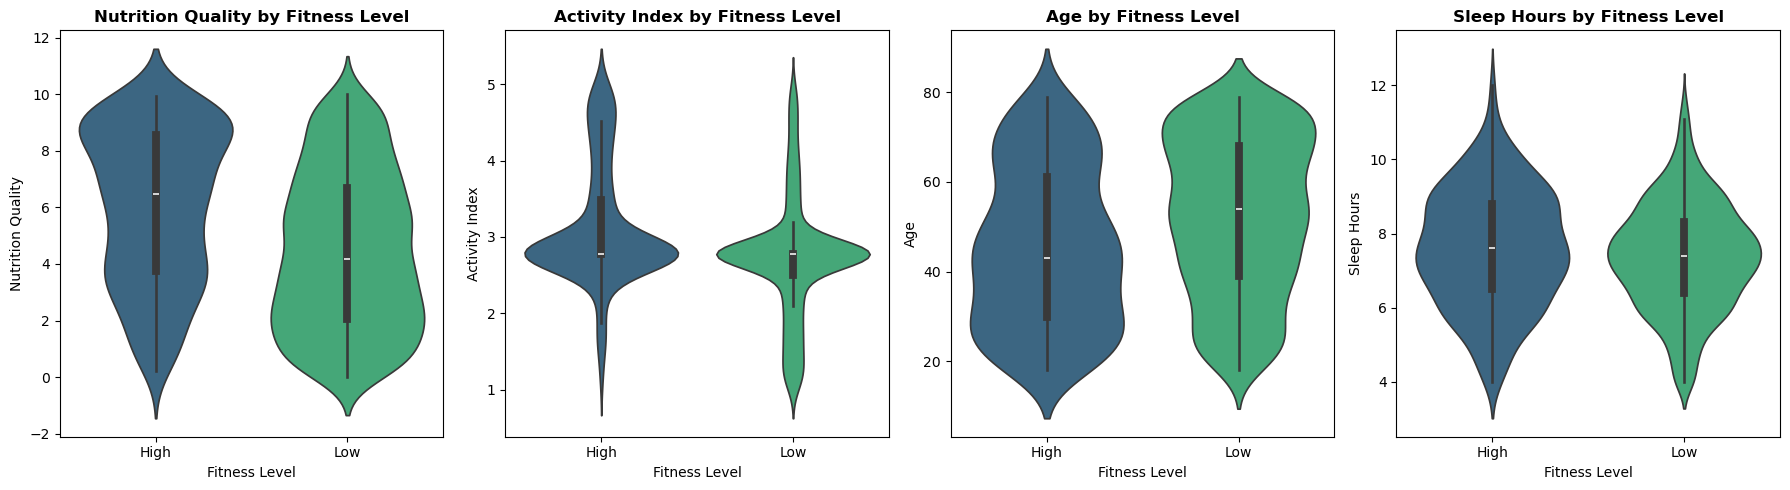

In [15]:
key_features = ['Nutrition Quality', 'Activity Index', 'Age', 'Sleep Hours']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(key_features):
    sns.violinplot(data=df_clean, x='Fitness Level', y=col, hue='Fitness Level',
                   palette='viridis', legend=False, ax=axes[i])
    axes[i].set_title(f'{col} by Fitness Level', fontweight='bold')
plt.tight_layout()
plt.show()

**Draft notes:**

- These four features were chosen because they showed the strongest (though still modest) relationship with Fitness Level in the correlation check below — worth explaining *why* you picked these four rather than just showing all eight.
- Look for shifts in the shape/median of each violin between High and Low groups, not just whether the boxes overlap.

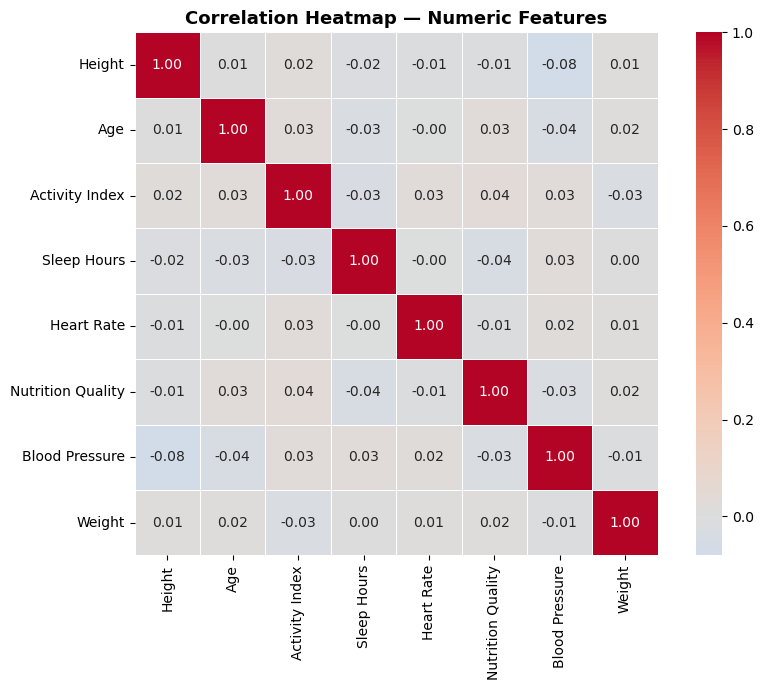

In [16]:
numeric_cols = ['Height', 'Age', 'Activity Index', 'Sleep Hours', 'Heart Rate',
                'Nutrition Quality', 'Blood Pressure', 'Weight']

corr_matrix = df_clean[numeric_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Correlation Heatmap — Numeric Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

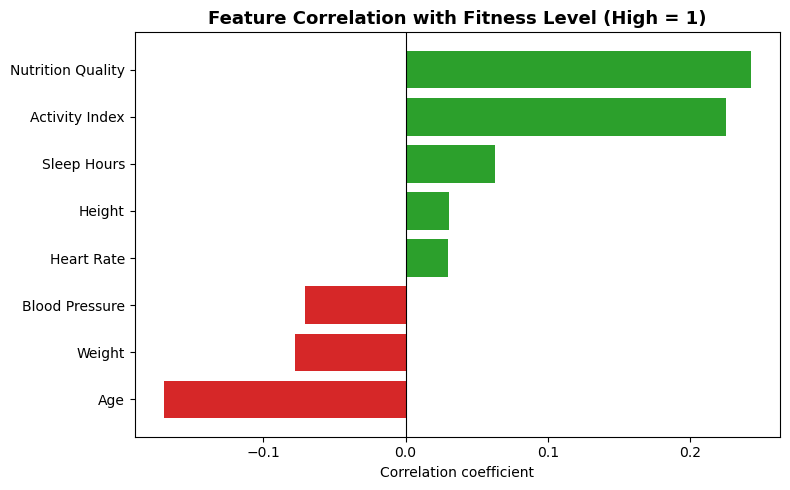

In [17]:
df_clean['Fitness_binary'] = (df_clean['Fitness Level'] == 'High').astype(int)
target_corr = df_clean[numeric_cols + ['Fitness_binary']].corr()['Fitness_binary'].drop('Fitness_binary').sort_values()

plt.figure(figsize=(8, 5))
colors = ['#d62728' if v < 0 else '#2ca02c' for v in target_corr.values]
plt.barh(target_corr.index, target_corr.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Feature Correlation with Fitness Level (High = 1)', fontsize=13, fontweight='bold')
plt.xlabel('Correlation coefficient')
plt.tight_layout()
plt.show()

**Draft notes:**

- Feature-to-feature correlations (the heatmap) are all very weak — no strong multicollinearity between the numeric predictors.
- Feature-to-target correlations are modest but clearest for **Nutrition Quality (+0.24)**, **Activity Index (+0.23)**, and **Age (-0.17)** — i.e. better nutrition and more activity lean toward "High" fitness, older age leans toward "Low."
- None of these correlations are strong on their own — worth being honest about that rather than overstating it. This suggests Fitness Level isn't explained well by any single feature in isolation, which is itself an insight (and a reason multivariate/clustering techniques are worth trying next).


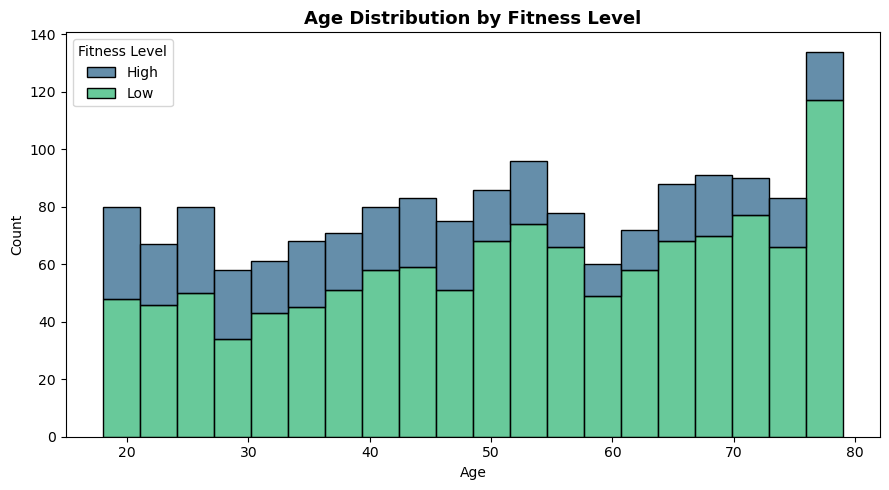

In [18]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x='Age', hue='Fitness Level', multiple='stack', bins=20, palette='viridis')
plt.title('Age Distribution by Fitness Level', fontsize=13, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

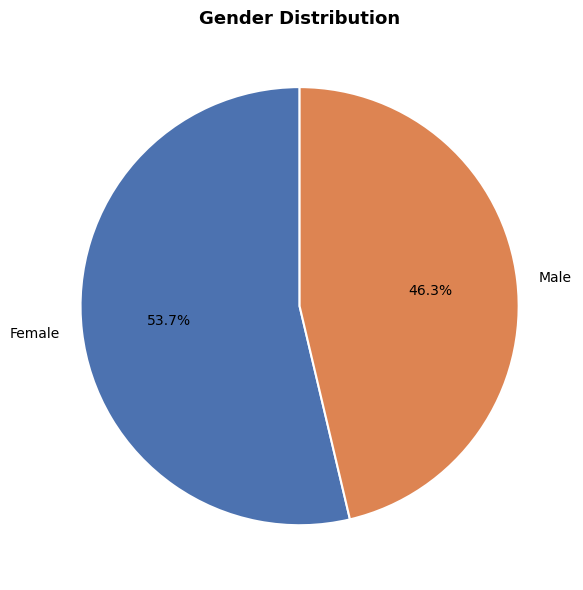

In [19]:
gender_counts = df_clean['Gender'].value_counts()

plt.figure(figsize=(6, 6))
colors = ['#4C72B0', '#DD8452']
plt.pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',
        colors=colors, startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
plt.title('Gender Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

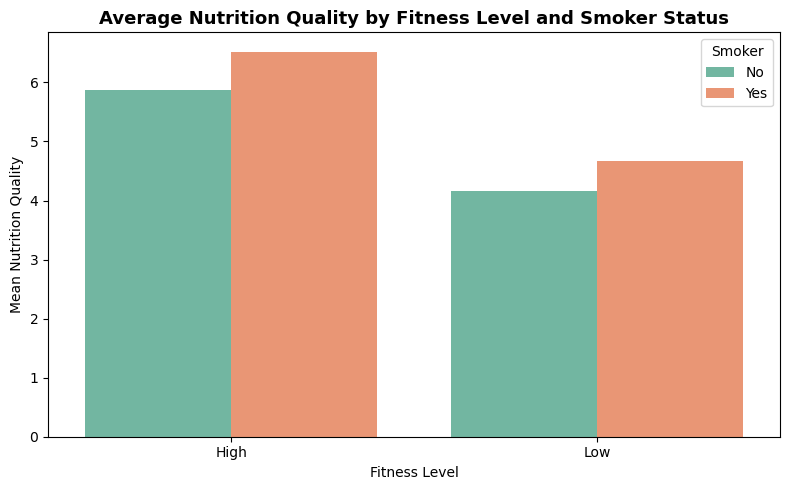

In [20]:
grp = df_clean.groupby(['Fitness Level', 'Smoker'])['Nutrition Quality'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=grp, x='Fitness Level', y='Nutrition Quality', hue='Smoker', palette='Set2')
plt.title('Average Nutrition Quality by Fitness Level and Smoker Status', fontsize=13, fontweight='bold')
plt.ylabel('Mean Nutrition Quality')
plt.tight_layout()
plt.show()

**Draft notes:**

- **Histogram:** Age distribution looks fairly even across the range for the "Low" group, but check whether "High" fitness skews toward any particular age band — this ties back to the -0.17 correlation found earlier (older leaning slightly toward "Low").
- **Pie chart:** Gender split is close to even (869 Female / 740 Male, ~54%/46%) — not a major imbalance, but we checked it as part of understanding the dataset's composition.
- **Bar chart:** this one throws up something worth talking through critically rather than glossing over — smokers show a *higher* average Nutrition Quality than non-smokers in both fitness groups, which runs against intuition. This a real pattern, a coincidence in a synthetic dataset, or a sign the two variables aren't really related and this small difference is just noise? 